# ACCESS-OM3 and ACCESS-OM2 horizontal mean temperature and salinity Hovmollers: drift from initial condition, vs depth and time

Related issue: https://github.com/ACCESS-Community-Hub/access-om3-25km-paper-1/issues/8

Run with a lot of cores (say, 28).

In [1]:
# These first two cells must be in all notebooks!
# It allows us to run all the notebooks at once, this cell has a tag "parameters" which allows us to pass in 
# arguments externally using papermill (see mkfigs.sh for details)

# Set esm_file to the datastore for the main experiment of interest
# esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-00532b88/datastore.json"
esm_file = "/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test4-d28e0359/datastore.json"
# esm_file = '/scratch/x77/aek156/access-om3/archive/MC_25km_jra_iaf+wombatlite-test5-38867fcd/datastore.json'
# esm_file = '/scratch/x77/aek156/access-om3/archive/MC_25km_era_iaf+wombatlite-test5-era-8a51ed1d/datastore.json'
# esm_file = '/scratch/x77/aek156/access-om3/archive/MC_25km_jra_iaf+wombatlite-test-test5-tweaks-dd8d35ed/datastore.json'
#esm_file = "/g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-27-07-2026-PD-control/cm3-datastore/cm3-datastore.json"

# papermill settings. *No need to modify these if running interactively.* 
papermill = False                      # `cwd` and `nbname` will be populated by papermill.
cwd = None                             # current working directory 
nbname = None                          # notebook name

In [2]:
# Parameters
esm_file = "/g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-27-07-2026-PI-control/cm3-datastore/cm3-datastore.json"
papermill = True
cwd = "/g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/"
nbname = "temp-salt-vs-depth-time.ipynb"


In [3]:
import os
if not papermill: 
    import nci_ipynb  # requires conda/analysis3-26.03 or later
    cwd = nci_ipynb.dir()
    nbname = nci_ipynb.name()
    os.chdir(cwd)
import mkfigs_bootstrap  # noqa: adds external/access-model-mkfigs/src to sys.path (stop-gap)
from mkfigs import MkmdWriter
mkmd = MkmdWriter(esm_file, nbname, str(cwd), pm=papermill)
from exptdata_access import guess_experiment_from_esm_file
# Infer model information from the datastore path
expt_key, info = guess_experiment_from_esm_file(esm_file)
model_name = info["model"]             # OM3 or CM3
print(f"Running notebook for model: {model_name}")
print("ESM datastore path:", esm_file)

Running notebook for model: ACCESS-CM3
ESM datastore path: /g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-27-07-2026-PI-control/cm3-datastore/cm3-datastore.json


In [4]:
IAF = esm_file.find('iaf') > 0
IAF

False

In [5]:
import os
import numpy as np
import xarray as xr
import cftime
import cf_xarray as cfxr
import cf_xarray.units
import pint_xarray
from pint import application_registry as ureg
import intake
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import matplotlib as mpl
from distributed import Client
import cmocean as cm
import cartopy.crs as ccrs
import cartopy.feature as cft
from shapely import geometry
from textwrap import wrap
from tqdm.notebook import tqdm
xr.set_options(keep_attrs=True);  # cf_xarray works best when xarray keeps attributes by default

In [6]:
import warnings
warnings.simplefilter(action='ignore', category=FutureWarning)

In [7]:
from model_agnostic import patch_broken_conda_env, patch_dask_workers
patch_broken_conda_env()   # no-op on healthy conda envs
client = Client(threads_per_worker=1)
patch_dask_workers(client) # patch the dask workers too
client

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 16
Total threads: 16,Total memory: 188.56 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:41845,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:38109,Total threads: 1
Dashboard: http://127.0.0.1:44501/status,Memory: 11.78 GiB
Nanny: tcp://127.0.0.1:43247,


## Define regions

Text(0.5, 1.0, 'Regions (BUG: incorrect shapes north of 65°N)')

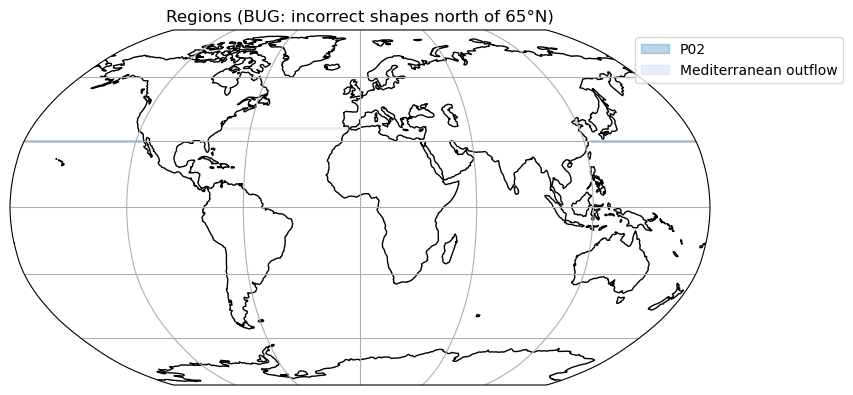

In [8]:
regions = { # [minx, maxx, miny, maxy], using model longitude range (-280 to 80)
    # "Global": [-280, 80, -90, 90],
    # "Arctic": [-280, 80, 65, 90],
    # "Southern Ocean": [-280, 80, -82, -63],
    # "ACC": [-280, 80, -63, -45],
    # "Southern Pacific": [-210, -70, -45, -20],
    # "Tropical Pacific": [-240, -100, -20, 20],
    # "North Pacific": [-240, -100, 20, 65],
    # "South Atlantic": [-60, 20, -45, -20],
    # "Tropical Atlantic": [-70, 20, -20, 20],
    #"North Atlantic": [-100, 0, 20, 65],
    # "Indian": [30, 120, -45, 20],
    # "Aegean Sea": [18, 27.5, 34, 44],
    #"Black Sea": [27.5, 43, 40.5, 48],
    # "Baltic Sea": [13, 30, 53, 58],
    # "Mediterranean Sea": [0, 35, 31, 41],
    # "Red Sea": [33, 44, 12, 29],
    # "Persian Gulf": [47, 56, 24, 31],
    # "White Sea": [31, 41, 63, 68],
# the following are from Transects.ioynb
    # 'SR3': [140-360, 140-360, -67, -42], # to match Kiss et al 2020
    # 'P16': [-150, -150, -76, 61], # to match Kiss et al 2020
    # 'A16': [-25, -25, -75.01, 65], # to match Kiss et al 2020
    # 'I08-09': [95-360, 95-360, -65, 15.1], # to match Kiss et al 2020
    'P02': [ -237, -117, 30, 30],
    # 'P04': [ -235, -85, 9.5, 9.5],
    # 'P06': [ -207, -72, -32.5, -32.5],
    # 'OSNAP': [-62, -5, 59, 59], # only roughly near OSNAP
    # 'A02': [-52, -5, 48, 48], # only roughly near A02
    # 'A05': [-96, -17, 24.5, 24.5],
    # 'A10': [-50, 17, -30, -30],
    'Mediterranean outflow': [-75, -6, 36, 36],
    # 'I05 west': [29, 80, -33, -33],
    # 'I05 east': [-280, -246, -33, -33],
}
regions = {k: dict(zip(["minx", "maxx", "miny", "maxy"], v)) for k, v in regions.items()}  # convert to dicts

for r, d in regions.items():
    for k, x in d.items():
        if k in ["minx", "maxx"] and x != max(-280, min(x, 80)):
            raise ValueError(f"{r} {k} = {x} is outside the range -280 to 80")

fig = plt.figure(figsize=(10, 4))

colors = mpl.color_sequences['tab20']
try:  # set Global color to white 
    colors[list(regions.keys()).index("Global")] = (1, 1, 1)
except ValueError:
    pass

ax = plt.axes(position=[0.05,0.05,0.7,0.9], projection=ccrs.Robinson())
ax.coastlines(resolution="110m")
ax.gridlines(draw_labels=False)

legend_elements = []
for i, (region, limits) in enumerate(regions.items()):
    ax.add_geometries([geometry.box(**limits)], crs=ccrs.PlateCarree(), color=colors[i], alpha=0.3)
    legend_elements.append(Patch(color=colors[i], alpha=0.3, label=region))

ax.legend(handles=legend_elements, bbox_to_anchor=(1.2, 1.00))
plt.title("Regions (BUG: incorrect shapes north of 65°N)")

## Load data from ACCESS-OM3

In [9]:
if model_name == "ACCESS-CM3":
    catalogs = [esm_file]
else:
    catalogs = [
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-5165c0f8/datastore.json',
                # '/g/data/ol01/access-om3-output/access-om3-025/25km-iaf-test-for-AK-expt-7df5ef4c/datastore.json',
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-5165c0f8/datastore.json',
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-gm1-d968c801/datastore.json',
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-gm2-5dc49da6/datastore.json',
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-gm3-da330542/datastore.json',
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-gm4-9fd08880/datastore.json',
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf-1.0-beta-gm5-9b5dbfa9/datastore.json',
                esm_file,
                # '/scratch/tm70/aek156/access-om3/archive/MC_25km_jra_iaf+wombatlite-test4-rerun-099ed2b5/datastore.json',
                # '/scratch/tm70/aek156/access-om3/archive/MC_25km_jra_iaf+wombatlite-test5test-67872f64/datastore.json',
                '/scratch/x77/aek156/access-om3/archive/MC_25km_jra_iaf+wombatlite-test5-38867fcd/datastore.json',
                # '/scratch/x77/aek156/access-om3/archive/MC_25km_era_iaf+wombatlite-test5-era-8a51ed1d/datastore.json',
                '/scratch/x77/aek156/access-om3/archive/MC_25km_jra_iaf+wombatlite-test-test5-tweaks-dd8d35ed/datastore.json',
                '/scratch/x77/aek156/access-om3/archive/MC_25km_jra_iaf+wombatlite-test5.1-8f50b769/datastore.json',
                # '/g/data/ol01/outputs/access-om3-25km/MC_25km_jra_iaf+wombatlite-test3v2-COARE-12fab415/datastore.json',
            ]
    if not IAF:
        catalogs = [esm_file]  # the IAF comparison runs above don't share model years with an RYF run
catalogs

['/g/data/zv30/non-cmip/ACCESS-CM3/cm3-run-27-07-2026-PI-control/cm3-datastore/cm3-datastore.json']

In [10]:
# helper for loading area
def get_area_var(ds, candidates=("areacello", "area_t")): 
    for v in candidates:
        sub = ds.search(variable=v)
        if len(sub.df):
            dvars = sub.to_dask()
            return dvars[list(dvars.data_vars)[0]]
    raise ValueError(f"No area variable found among {candidates}")

In [11]:
from exptdata_access import get_exptname_from_path
# Comparison datastores on another project's /scratch (e.g. x77) are only readable if the
# job requested that storage; skip any that aren't reachable rather than failing the whole notebook.
for c in [c for c in catalogs if c != esm_file and not os.path.exists(c)]:
    print(f"{c} not found - omitted")
catalogs = [c for c in catalogs if c == esm_file or os.path.exists(c)]
om3datastores = { get_exptname_from_path(c):
               intake.open_esm_datastore(c,
                                         columns_with_iterables=[
                                            "variable",
                                            "variable_long_name",
                                            "variable_standard_name",
                                            "variable_cell_methods",
                                            "variable_units"]
                                        )
              for c in catalogs }
om3datastores

{'cm3-run-27-07-2026-PI-control': <cm3-datastore catalog with 22 dataset(s) from 7000 asset(s)>}

In [12]:
om3varnames = [ 'thetao', 'so' ]
om3varnames_i = [ # variables on interfaces
                # # 'difvho', # Kd_heat: Total diapycnal diffusivity for heat at interfaces
                # # 'difvso', # Kd_salt: Total diapycnal diffusivity for salt at interfaces
                # 'Kd_interface', # Total diapycnal diffusivity at interfaces (min of Kd_heat, Kd_salt - see https://github.com/ACCESS-NRI/access-om3-configs/issues/1046#issuecomment-5312597952 )
                # 'Kd_ePBL', # ePBL diapycnal diffusivity at interfaces
                # 'Kd_shear', # Shear-driven Diapycnal Diffusivity at horizontal tracer points
                # 'Kd_bkgnd', # Background diffusivity added by MOM_bkgnd_mixing module
                # 'Kd_itides', # Internal Tide Driven Diffusivity
                # 'Kd_BBL', # Bottom Boundary Layer Diffusivity
                # # #     # 'rsdoabsorb'
              ]
om3varnames += om3varnames_i

# whole columns and rows, with "auto" latitude chunks (~128 MB) at any resolution: a whole 3-D field per
# chunk is ~4 GB at 8km, which kills the dask workers
om3chunks = {"xh": -1, "yh": "auto", "z_l": -1, "zi": -1}

if model_name == "ACCESS-CM3":
    om3chunks["time"] = 1  # CM3 stores yearly files; avoid ~6 GB chunks

om3vars = {
    vname: {expt: ds.search(variable=vname).to_dask(
                xarray_open_kwargs = dict(
                    chunks=om3chunks,
                    decode_timedelta=True
                )
            )[vname]
            for expt, ds in om3datastores.items()
          }
    for vname in om3varnames
    }

om3area = {expt: get_area_var(ds) for expt, ds in om3datastores.items()} # get area for weighting - NOT TESTED FOR CM3 YET

# omit latitudes with grid bug in this run https://github.com/ACCESS-NRI/ocean_model_grid_generator/issues/7
for vname, d in om3vars.items():
    try:
        d['25km-iaf-test-for-AK-expt-7df5ef4c'] = d['25km-iaf-test-for-AK-expt-7df5ef4c'].isel(yh=slice(10, None))
    except ValueError:
        d['25km-iaf-test-for-AK-expt-7df5ef4c'] = d['25km-iaf-test-for-AK-expt-7df5ef4c'].isel(yq=slice(10, None))
    except KeyError:
        pass
        
# same fix to area
try:
    om3area['25km-iaf-test-for-AK-expt-7df5ef4c'] = om3area['25km-iaf-test-for-AK-expt-7df5ef4c'].isel(yh=slice(10, None))
except (ValueError, KeyError):
    pass
    
if IAF:
    for vname, d in om3vars.items():
        for expt in d:
            try:
                d[expt] = d[expt].convert_calendar("proleptic_gregorian", use_cftime=True)
            except KeyError:
                pass

# mask out vanished layers for variables on model native coordinates
for v in om3vars:
    for expt, da in om3vars[v].items():
        if 'zi' in om3vars[v][expt].dims:
            depth = om3datastores[expt].search(variable='deptho').to_dask()['deptho']
            om3vars[v][expt] = da.where(da.zi < depth)
        if 'zl' in om3vars[v][expt].dims:
            depth = om3datastores[expt].search(variable='deptho').to_dask()['deptho']
            om3vars[v][expt] = da.where(da.zl < depth)

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/intake_esm/source.py:316: ConcatenationWarning: Attempting to concatenate datasets without valid dimension coordinates: retaining only first dataset. Request valid dimension coordinate to silence this warning.
  warnings.warn(


## Load data from ACCESS-OM2
use control - see https://forum.access-hive.org.au/t/access-om2-control-experiments/258#p-747-ryf-7

In [13]:
if model_name == "ACCESS-CM3":
    data_name = 'ACCESS-CM2'
    om2exptname = 'cj877'  # CM2 control archive on /g/data/p73 (same reference as pPV.ipynb)
else:
    data_name = 'ACCESS-OM2'
    if IAF:
        om2exptname = '025deg_jra55_iaf_omip2_cycle1'
    else:
        om2exptname = '025deg_jra55_ryf9091_gadi'  # monthly temp only for 1900-1903, and 2300-, with annual data in the gap
    om2datastores = {om2exptname: intake.cat.access_nri[om2exptname]}

In [14]:
om2varnames = [ 'temp', 'salt' ]

if model_name == "ACCESS-CM3":
    # Reference: ACCESS-CM2 cj877 control archive (same source as pPV.ipynb and
    # Overturning_in_ACCESS_OM3.ipynb). These panels show how temperature and salinity
    # EVOLVE -- drift and stabilisation during spin-up -- so the reference has to cover
    # the same integration length measured from the same point in each run's spin-up:
    # cj877's first `cm3_nyears` model years, where cm3_nyears is the length of the CM3
    # record (derived below, not hardcoded). The whole period is kept rather than the
    # last NYEARS, because the drift itself is the signal. cj877's equilibrated tail is
    # not comparable: its global-mean ocean temperature rises ~0.7 K between model
    # years 50 and 502, which would read as a model difference rather than spin-up.
    from pathlib import Path
    from model_agnostic import complete_years
    cm2_dir = Path("/g/data/p73/archive/CMIP6/non-CMIP/ACCESS-CM2/cj877/history/ocn")

    cm3_time = next(iter(om3vars[om3varnames[0]].values())).time
    cm3_nyears = len(complete_years(cm3_time))
    print(f"CM3 record: {cm3_nyears} complete years; using cj877 model years 1-{cm3_nyears}")

    def _load_cm2(varname):
        files = sorted(cm2_dir.glob(f"ocean-3d-{varname}-1-monthly-mean-ym_*.nc"))
        if not files:
            raise FileNotFoundError(f"No cj877 monthly files found for {varname!r}")
        files = [f for f in files if int(f.stem.split("_")[-2]) <= cm3_nyears]
        if not files:
            raise FileNotFoundError(f"No cj877 {varname!r} files found for years 1-{cm3_nyears}")
        ds = xr.open_mfdataset(
            files,
            combine="by_coords",
            parallel=True,
            chunks={"time": 1, "xt_ocean": -1, "yt_ocean": -1, "st_ocean": -1},
            decode_timedelta=True,
            use_cftime=True,  # cj877 model years can't be datetime64
            data_vars="minimal", coords="minimal", compat="override",
        )
        return ds[varname]

    om2vars = { vname: {om2exptname: _load_cm2(vname)} for vname in om2varnames }

    # Relabel the CM2 control-run times onto the CM3 time axis so the panels can
    # share the x-axis (same approach as Overturning_in_ACCESS_OM3.ipynb) — this
    # also avoids mixing cftime and datetime64 axes, which matplotlib can't share.
    # Both records are aligned from their START, so model year 1 of cj877 sits under
    # the first year of the CM3 run and equal elapsed integration times line up.
    for vname, dd in om2vars.items():
        for expt, da in dd.items():
            n = min(da.sizes["time"], cm3_time.sizes["time"])
            if da.sizes["time"] != cm3_time.sizes["time"]:
                print(f"Aligning {expt} {vname} with first {n} time steps")
            dd[expt] = (da.isel(time=slice(0, n))
                          .assign_coords(time=("time", cm3_time.isel(time=slice(0, n)).values)))

    # cj877/history/ocean_grid.nc does not exist in the relocated archive;
    # the statics live beside the history files as per-variable files.
    grid_file = cm2_dir / "ocean-2d-area_t.nc"
    om2area = {om2exptname: xr.open_dataset(grid_file)["area_t"]}  # get area for weighting

else:
    om2vars = {
        vname: {expt: ds.search(variable=vname, frequency="1mon").to_dask(
                    xarray_open_kwargs = dict(
                        chunks={"xt_ocean": -1, "yt_ocean": -1, "st_ocean" : -1},  # remove "yt_ocean": -1 for resolution finer than 25km
                        decode_timedelta=True
                    )
                )[vname]
                for expt, ds in om2datastores.items()
              }
        for vname in om2varnames
        }
    
    om2area = {om2exptname: get_area_var(om2datastores[om2exptname])} # get area for weighting

    if not IAF:
        # RYF: compare with the OM2 RYF control over the same model years as the OM3 run (it runs to
        # year 2550, which would squash the OM3 record on the shared time axis). It saved monthly
        # temp/salt only for 1900-1903 (and from 2300), with annual means in between, so use monthly
        # data where there is some and annual means for the other years.
        om3time = om3vars[om3varnames[0]][get_exptname_from_path(esm_file)].time
        y0, y1 = int(om3time.dt.year.min()), int(om3time.dt.year.max())
        for vname, d in om2vars.items():
            for expt, da in d.items():
                mon = da.sel(time=slice(f"{y0:04d}", f"{y1:04d}"))
                ann = om2datastores[expt].search(variable=vname, frequency="1yr").to_dask(
                    xarray_open_kwargs=dict(chunks={"xt_ocean": -1, "yt_ocean": -1, "st_ocean": -1},
                                            decode_timedelta=True, use_cftime=True)
                )[vname].sel(time=slice(f"{y0:04d}", f"{y1:04d}"))
                ann = ann.sel(time=~ann.time.dt.year.isin(np.unique(mon.time.dt.year)))
                if ann.sizes["time"]:
                    mon = xr.concat([mon, ann], dim="time", coords="minimal", compat="override").sortby("time")
                if mon.sizes["time"] == 0:
                    # no overlap in model years: use the start of the OM2 run, with the same number of years
                    mon = da.sel(time=slice(None, f"{int(da.time.dt.year[0]) + y1 - y0:04d}"))
                    print(f"WARNING: {expt} has no data in {y0}-{y1}; using its first {y1 - y0 + 1} years instead")
                d[expt] = mon
                print(f"{expt} {vname}: {d[expt].time.values[0]} to {d[expt].time.values[-1]}, {d[expt].sizes['time']} samples")
    
    if IAF:
        for vname, d in om2vars.items():
            for expt in d:
                try:
                    d[expt] = d[expt].convert_calendar("proleptic_gregorian", use_cftime=True)
                except KeyError:
                    pass

CM3 record: 50 complete years; using cj877 model years 1-50


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1469461c9070>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(
/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:50: UserWarning: An error occurred while loading the ArgoVis data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x146944da2360>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1477a93fe360>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x154f247bd6d0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:38: UserWarning: An error occurred while loading the ERDDAP data fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x1459021ac0b0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


... (142 outputs left out)

/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/argopy/utils/lists.py:107: UserWarning: An error occurred while loading the GDAC index fetcher, it will not be available !
<class 'requests.exceptions.ConnectionError'>
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x153ad3eaf7a0>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  warnings.warn(


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'argo' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x153ad3ea9460>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/g/data/xp65/public/apps/med_conda/envs/analysis3-26.08/lib/python3.12/site-packages/xarray/backends/plugins.py:109: RuntimeWarning: Engine 'erddapy' loading failed:
HTTPSConnectionPool(host='raw.githubusercontent.com', port=443): Max retries exceeded with url: /IrishMarineInstitute/awesome-erddap/master/erddaps.json (Caused by NewConnectionError('<urllib3.connection.HTTPSConnection object at 0x153ad097d670>: Failed to establish a new connection: [Errno 101] Network is unreachable'))
  external_backend_entrypoints = backends_dict_from_pkg(entrypoints_unique)


/jobfs/185314755.gadi-pbs/ipykernel_529362/3644845821.py:57: SerializationWarning: Unable to decode time axis into full numpy.datetime64 objects, continuing using cftime.datetime objects instead, reason: dates prior reform date (1582-10-15). To silence this warning specify 'use_cftime=True'.
  om2area = {om2exptname: xr.open_dataset(grid_file)["area_t"]}  # get area for weighting


# Set time range

In [15]:
firsttime = []
lasttime = []
for v, d in om3vars.items():
    for expt, da in d.items():
        firsttime.append(da.time.values[0])
        lasttime.append(da.time.values[-1])
for v, d in om2vars.items():
    for expt, da in d.items():
        firsttime.append(da.time.values[0])
        lasttime.append(da.time.values[-1])

if IAF:
    # datestop = cftime.DatetimeProlepticGregorian(2018, 12, 31, 12, 0, 0, 0, has_year_zero=True)  # to match OM2 IAF run
    datestart = max(firsttime) # latest first date in data
    datestop = min(lasttime) # earliest final date in data
    datelist = list(cftime.to_tuple(datestop))
    # datelist[0] -= 2
    datelist[0] -= 25-1  # last 25 years
    datestart = max(datestart, cftime.datetime(*datelist, calendar=datestop.calendar))
    # bracket to start/end of year
    datestart = cftime.datetime(cftime.to_tuple(datestart)[0],  1, 1, calendar=datestop.calendar)
    datestop  = cftime.datetime(cftime.to_tuple(datestop)[0], 12, 31, 23, 59, 59, calendar=datestop.calendar)
    timerange = slice(datestart, datestop)
    if datestart >= datestop:
        print('firsttime =', *firsttime, sep='\n')
        print('lasttime =', *lasttime, sep='\n')
        print('datestart =', datestart)
        print('datestop =', datestop)
        raise ValueError('datestart >= datestop')
# manually set range instead of using the above
    # timerange = slice(cftime.DatetimeProlepticGregorian(1958, 1, 1, 0, 0, 0, 0),
    #                   cftime.DatetimeProlepticGregorian(1959, 1, 1, 0, 0, 0, 0))
    # timerange = slice(cftime.DatetimeProlepticGregorian(1962, 1, 1, 0, 0, 0, 0),
    #                   cftime.DatetimeProlepticGregorian(1963, 1, 1, 0, 0, 0, 0))
# RYF: the whole OM3 record, with the OM2 RYF control over the same model years (selected above)

timerange = slice(None, None)  # all times: the Hovmollers show whole records
print('timerange =', timerange)

timerange = slice(None, None, None)


In [16]:
for v, d in om3vars.items():
    for expt, da in d.items():
        om3vars[v][expt] = da.sel(time=timerange)
for v, d in om2vars.items():
    for expt, da in d.items():
        om2vars[v][expt] = da.sel(time=timerange)

# Calculate Hovmollers for each region - SLOW!

In [17]:
def area_weighted_mean(da, area, dims):
    """area weighted mean using xarray.DataArray.weighted"""
    wet = np.isfinite(da.isel(time=0)) if "time" in da.dims else np.isfinite(da) # wet mask
    weights = area.broadcast_like(wet).where(wet).fillna(0) # set land weights to 0
    return da.weighted(weights).mean(dim=dims) # weighted mean across specified dims

## OM3

In [18]:
%%time
om3vars_hov = dict()
for region, b in tqdm(regions.items(), desc='regions'):
    om3vars_hov[region] = dict()
    minx, maxx, miny, maxy = b.values()
    meandims = []
    if minx == maxx:
        xsel = minx
        xmethod = "nearest"
    else:
        xsel = slice(minx, maxx)
        xmethod = None
        meandims.append("xh")
    if miny == maxy:
        ysel = miny
        ymethod = "nearest"
    else:
        ysel = slice(miny, maxy)
        ymethod = None
        meandims.append("yh")
    for vname, vdatadict in tqdm(om3vars.items(), desc=f'   {region} variables'):
        om3vars_hov[region][vname] = dict()
        for expt, da in tqdm(vdatadict.items(), desc=f'      {vname} experiments', ):
            om3vars_hov[region][vname][expt] = area_weighted_mean(
                        da.sel(xh=xsel, method=xmethod).sel(yh=ysel, method=ymethod),
                        om3area[expt].sel(xh=xsel, method=xmethod).sel(yh=ysel, method=ymethod),
                        dims=meandims,
                      ).load()

regions:   0%|          | 0/2 [00:00<?, ?it/s]

   P02 variables:   0%|          | 0/2 [00:00<?, ?it/s]

      thetao experiments:   0%|          | 0/1 [00:00<?, ?it/s]

      so experiments:   0%|          | 0/1 [00:00<?, ?it/s]

   Mediterranean outflow variables:   0%|          | 0/2 [00:00<?, ?it/s]

      thetao experiments:   0%|          | 0/1 [00:00<?, ?it/s]

      so experiments:   0%|          | 0/1 [00:00<?, ?it/s]

CPU times: user 1min 28s, sys: 32.5 s, total: 2min 1s
Wall time: 4min 14s


## OM2

In [19]:
%%time
om2vars_hov = dict()
for region, b in tqdm(regions.items(), desc='regions'):
    om2vars_hov[region] = dict()
    minx, maxx, miny, maxy = b.values()
    meandims = []
    if minx == maxx:
        xsel = minx
        xmethod = "nearest"
    else:
        xsel = slice(minx, maxx)
        xmethod = None
        meandims.append("xt_ocean")
    if miny == maxy:
        ysel = miny
        ymethod = "nearest"
    else:
        ysel = slice(miny, maxy)
        ymethod = None
        meandims.append("yt_ocean")
    for vname, vdatadict in tqdm(om2vars.items(), desc=f'   {region} variables'):
        om2vars_hov[region][vname] = dict()
        for expt, da in tqdm(vdatadict.items(), desc=f'      {vname} experiments', ):
            om2vars_hov[region][vname][expt] = area_weighted_mean(
                        da.sel(xt_ocean=xsel, method=xmethod).sel(yt_ocean=ysel, method=ymethod),
                        om2area[expt].sel(xt_ocean=xsel, method=xmethod).sel(yt_ocean=ysel, method=ymethod),
                        dims=meandims,
                      ).load()

regions:   0%|          | 0/2 [00:00<?, ?it/s]

   P02 variables:   0%|          | 0/2 [00:00<?, ?it/s]

      temp experiments:   0%|          | 0/1 [00:00<?, ?it/s]

      salt experiments:   0%|          | 0/1 [00:00<?, ?it/s]

   Mediterranean outflow variables:   0%|          | 0/2 [00:00<?, ?it/s]

      temp experiments:   0%|          | 0/1 [00:00<?, ?it/s]

      salt experiments:   0%|          | 0/1 [00:00<?, ?it/s]

CPU times: user 1min 18s, sys: 26.3 s, total: 1min 44s
Wall time: 5min 12s


# Plot Hovmollers for each region

In [20]:
def decimal_year(da):
    """
    Replace the time coordinate with decimal years, so that runs of any length and calendar share a
    time axis with plain year tick labels (cftime date tick labels overlap on short records, e.g. the
    10-year 8km run, and panels on different calendars can't share a cftime axis).
    """
    t = da.time
    cal = t.dt.calendar
    years = t.dt.year.values
    ndays = np.array([(cftime.datetime(y + 1, 1, 1, calendar=cal) - cftime.datetime(y, 1, 1, calendar=cal)).days
                      for y in years])
    frac = (t.dt.dayofyear.values - 1 + t.dt.hour.values / 24) / ndays
    return da.assign_coords(time=years + frac)

for hov in (om3vars_hov, om2vars_hov):
    for region in hov:
        for vname in hov[region]:
            for expt in hov[region][vname]:
                hov[region][vname][expt] = decimal_year(hov[region][vname][expt])

## Plot variables

In [21]:
def plot(om3variable = "thetao",  # can be None
            om2variable = "temp",  # can be None
            vmax = None,  # autorange if None
            mkmdfig=True):
    vmax_in = vmax
    for region, d in om3vars_hov.items():
        npanels = len(d[om3variable]) if om3variable else 0
        npanels += len(om2vars_hov[region][om2variable]) if om2variable else 0
        nrows = (npanels+1)//2
        fig, axs = plt.subplots(nrows, 2,
                                figsize=(9, 3*nrows),
                                sharex=True, sharey=True)

        minx, maxx, miny, maxy = regions[region].values()
        if minx == maxx:
            regionstr = f'{minx}°E, {miny} to {maxy}°N'
        elif miny == maxy:
            regionstr = f'{minx}°E to {maxx}°E, {miny}°N'
        else:
            regionstr = f'{minx}°E to {maxx}°E, {miny}°N to {maxy}°N'

        fig.suptitle(f'Depth-time Hovmollers\naveraged over {region} ({regionstr})')

        if vmax_in:
            vmax = vmax_in
            vmin = -vmax
        else: # calculate range over all panels (different for each region)
            vmax = -1e32
            if om3variable:
                for i, (expt, da) in enumerate(d[om3variable].items(), start=1):
                    vmax = max(vmax, abs(da).max().data)
            if om2variable:
                for i2, (expt, da) in enumerate(om2vars_hov[region][om2variable].items(), start=i+1):
                    vmax = max(vmax, abs(da).max().data)
            vmin = 1e32
            if om3variable:
                for i, (expt, da) in enumerate(d[om3variable].items(), start=1):
                    vmin = min(vmin, abs(da).min().data)
            if om2variable:
                for i2, (expt, da) in enumerate(om2vars_hov[region][om2variable].items(), start=i+1):
                    vmin = min(vmin, abs(da).min().data)

        # ACCESS-OM3 (or ACCESS-CM3)
        if om3variable:
            for i, (expt, da) in enumerate(d[om3variable].items(), start=1):
                plt.subplot(nrows, 2, i)
                p = da.transpose().plot.contourf(
                    levels=101, vmin=vmin, vmax=vmax, extend="both" if vmax_in else None, cmap="seismic" if vmax_in else None, add_colorbar=False,
                )
                da.transpose().plot.contour(
                    levels=25, vmin=vmin, vmax=vmax, add_colorbar=False, colors=["k"], linewidths=[0.2], linestyles=["-"]
                )
                try:
                    zmax = da["z_l"][np.where(np.isnan(da.isel(time=0)))[0][0] - 1]
                    plt.gca().set_ylim([0, zmax])  # crop to deepest wet cell
                except (IndexError, KeyError):
                    plt.gca().set_ylim([0, None])  # no dry cells so show all
                plt.gca().invert_yaxis()
                plt.title(f"({chr(ord('a')+i-1)}) {model_name} {expt} {om3variable}", fontsize=8)
                plt.xlabel('Year')
                plt.ylabel('Depth [m]')
                label = f"{model_name}: {da.attrs['long_name']} ({om3variable}) [{da.attrs['units']}]"
    
        # ACCESS-OM2 (or ACCESS-CM2)
        if om2variable:
            for i2, (expt, da) in enumerate(om2vars_hov[region][om2variable].items(), start=i+1):
                plt.subplot(nrows, 2, i2)
                da.transpose().plot.contourf(
                    levels=101, vmin=vmin, vmax=vmax, extend="both" if vmax_in else None, cmap="seismic" if vmax_in else None, add_colorbar=False,
                )
                da.transpose().plot.contour(
                    levels=25, vmin=vmin, vmax=vmax, add_colorbar=False, colors=["k"], linewidths=[0.2], linestyles=["-"]
                )
                try:
                    zmax = da["st_ocean"][np.where(np.isnan(da.isel(time=0)))[0][0] - 1]
                    plt.gca().set_ylim([0, zmax])  # crop to deepest wet cell
                except (IndexError, KeyError):
                    plt.gca().set_ylim([0, None])  # no dry cells so show all
                plt.gca().invert_yaxis()
                plt.title(f"({chr(ord('a')+i2-1)}) {data_name} {expt} {om2variable}", fontsize=8)
                plt.xlabel('Year')
                plt.ylabel('Depth [m]')
                label += f"\n{data_name}: {da.attrs['long_name']} ({om2variable}) [{da.attrs['units']}]"
    
        try:  # drop empty subfigs (if any)
            fig.delaxes(axs.flatten()[i2])
        except UnboundLocalError:
            try: 
                fig.delaxes(axs.flatten()[i])
            except (IndexError, UnboundLocalError):
                pass
        except (IndexError, UnboundLocalError):
            pass
        for ax in fig.get_axes():
            ax.label_outer()
        plt.tight_layout()
        fig.colorbar(p, ax=axs, orientation='horizontal',
                     fraction=.1, shrink=0.7, aspect=40,
                     label=label)
        if mkmdfig:
            mkmd.savefig(fig, "Horizontal mean temperature and salinity Hovmollers", 
                         f"{model_name} and {data_name} horizontal mean "+om3variable+" Hovmollers vs depth and time. [GitHub issue: Hovmoller temperature anomaly (depth-time)](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/8)")            

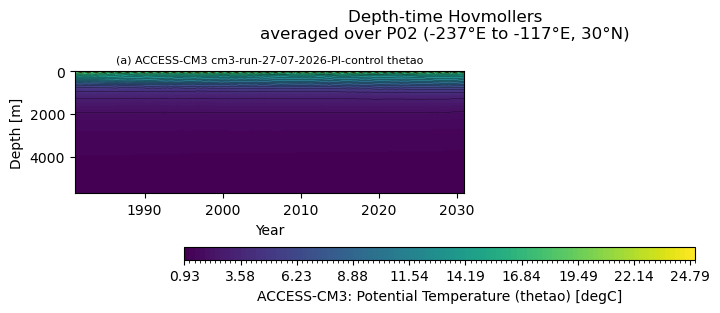

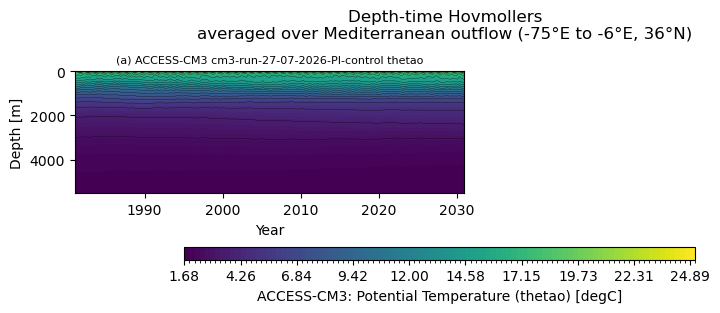

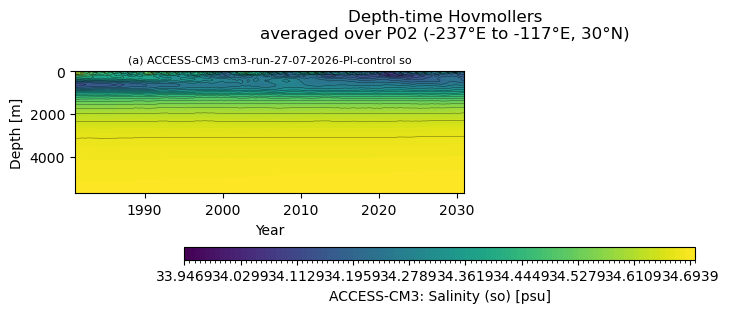

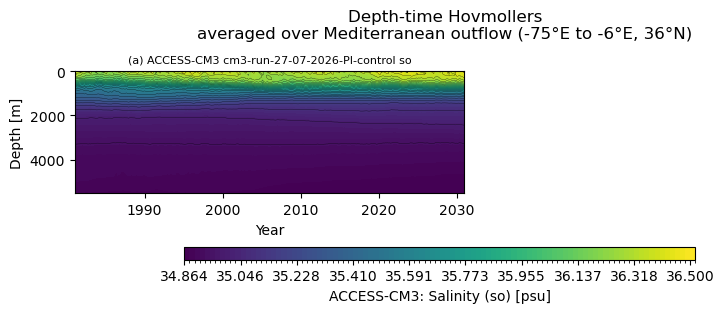

In [22]:
for vname in om3varnames:
    plot(om3variable = vname,
            om2variable = None,
            mkmdfig=False)

## Plot anomalies relative to initial state of first OM3 or OM2 plotted

In [23]:
def plot_anom(om3variable = "thetao",
            om2variable = "temp",
            vmax = None, mkmdfig=True):
    for region, d in om3vars_hov.items():
        npanels = len(d[om3variable]) if om3variable else 0
        npanels += len(om2vars_hov[region][om2variable]) if om2variable else 0
        nrows = (npanels+1)//2
        fig, axs = plt.subplots(nrows, 2,
                                figsize=(9, 3*nrows),
                                sharex=True, sharey=True)

        minx, maxx, miny, maxy = regions[region].values()
        if minx == maxx:
            regionstr = f'{minx}°E, {miny} to {maxy}°N'
        elif miny == maxy:
            regionstr = f'{minx}°E to {maxx}°E, {miny}°N'
        else:
            regionstr = f'{minx}°E to {maxx}°E, {miny}°N to {maxy}°N'

        fig.suptitle(f'Depth-time Hovmollers of anomaly relative to initial state of first OM3 or OM2 plotted,\naveraged over {region} ({regionstr})')

        if vmax == None: # calculate max abs over all panels (different for each region)
            vmax = 0
            if om3variable:
                for i, (expt, da) in enumerate(d[om3variable].items(), start=1):
                    if i == 1:
                        ref = da.isel(time=0)  # use the same reference state for all om3 expts in this region
                    vmax = max(vmax, abs(da - ref).max().data)
            if om2variable:
                for i2, (expt, da) in enumerate(om2vars_hov[region][om2variable].items(), start=i+1):
                    if i2 == i+1:
                        ref = da.isel(time=0)  # use the same reference state for all om2 expts in this region
                    vmax = max(vmax, abs(da - ref).max().data)

        # ACCESS-OM3 (or ACCESS-CM3)
        if om3variable:
            for i, (expt, da) in enumerate(d[om3variable].items(), start=1):
                plt.subplot(nrows, 2, i)
                if i == 1:
                    ref = da.isel(time=0)  # use the same reference state for all om3 expts in this region
                p = (da - ref).transpose().plot.contourf(
                    levels=101, vmin=-vmax, vmax=vmax, extend="both", cmap="seismic", add_colorbar=False,
                )
                (da - ref).transpose().plot.contour(
                    levels=25, vmin=-vmax, vmax=vmax, add_colorbar=False, colors=["k"], linewidths=[0.2], linestyles=["-"]
                )
                try:
                    zmax = da["z_l"][np.where(np.isnan(da.isel(time=0)))[0][0] - 1]
                    plt.gca().set_ylim([0, zmax])  # crop to deepest wet cell
                except (IndexError, KeyError):
                    plt.gca().set_ylim([0, None])  # no dry cells so show all
                plt.gca().invert_yaxis()
                plt.title(f"({chr(ord('a')+i-1)}) {model_name} {expt} {om3variable}", fontsize=8)
                plt.xlabel('Year')
                plt.ylabel('Depth [m]')
                label = f"{model_name}: {da.attrs['long_name']} ({om3variable}) difference [{da.attrs['units']}]"
    
        # ACCESS-OM2 (or ACCESS-CM2)
        if om2variable:
            for i2, (expt, da) in enumerate(om2vars_hov[region][om2variable].items(), start=i+1):
                plt.subplot(nrows, 2, i2)
                if i2 == i+1:
                    ref = da.isel(time=0)  # use the same reference state for all om2 expts in this region
                (da - ref).transpose().plot.contourf(
                    levels=101, vmin=-vmax, vmax=vmax, extend="both", cmap="seismic", add_colorbar=False,
                )
                (da - ref).transpose().plot.contour(
                    levels=25, vmin=-vmax, vmax=vmax, add_colorbar=False, colors=["k"], linewidths=[0.2], linestyles=["-"]
                )
                try:
                    zmax = da["st_ocean"][np.where(np.isnan(da.isel(time=0)))[0][0] - 1]
                    plt.gca().set_ylim([0, zmax])  # crop to deepest wet cell
                except (IndexError, KeyError):
                    plt.gca().set_ylim([0, None])  # no dry cells so show all
                plt.gca().invert_yaxis()
                plt.title(f"({chr(ord('a')+i2-1)}) {data_name} {expt} {om2variable}", fontsize=8)
                plt.xlabel('Year')
                plt.ylabel('Depth [m]')
                label += f"\n{data_name}: {da.attrs['long_name']} ({om2variable}) difference [{da.attrs['units']}]"
    
        try:  # drop empty subfigs (if any)
            fig.delaxes(axs.flatten()[i2])
        except UnboundLocalError:
            fig.delaxes(axs.flatten()[i])
        except (IndexError, UnboundLocalError):
            pass
        for ax in fig.get_axes():
            ax.label_outer()
        plt.tight_layout()
        fig.colorbar(p, ax=axs, orientation='horizontal',
                     fraction=.1, shrink=0.7, aspect=40,
                     label=label)
        if mkmdfig:
            mkmd.savefig(fig, "Horizontal mean temperature and salinity Hovmollers", 
                         f"{model_name} and {data_name} horizontal mean "+om3variable+" Hovmollers: drift from initial condition, vs depth and time. [GitHub issue: Hovmoller temperature anomaly (depth-time)](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/8)")            

In [24]:
for vname in om3varnames_i:
    plot_anom(om3variable = vname,
            om2variable = None,
            vmax = 0.005,
            mkmdfig=False)

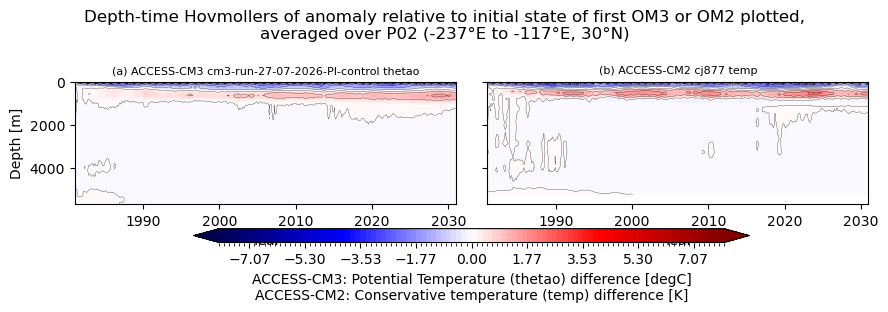

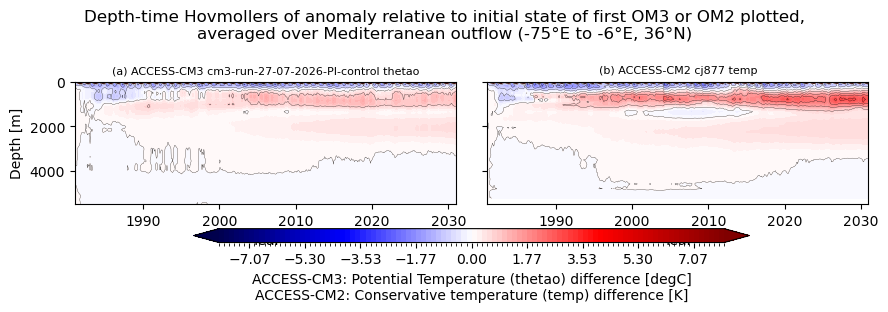

In [25]:
plot_anom(om3variable = "thetao",
        om2variable = "temp",
        mkmdfig=False)

Saved /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/temp-salt-vs-depth-time_01.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/temp-salt-vs-depth-time.md


Lines appended to /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/temp-salt-vs-depth-time.md successfully.


Saved /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/temp-salt-vs-depth-time_02.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/temp-salt-vs-depth-time.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/temp-salt-vs-depth-time.md successfully.


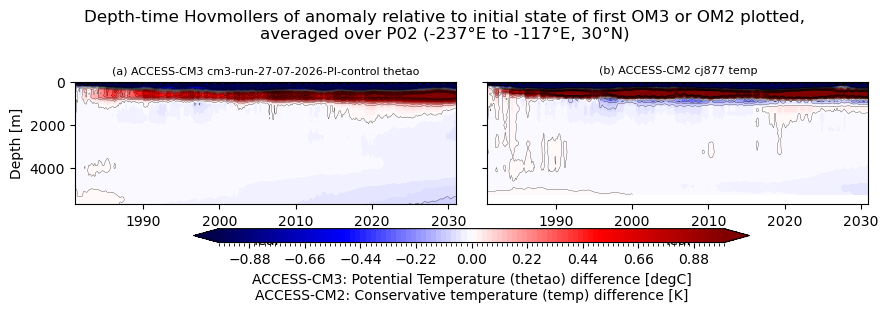

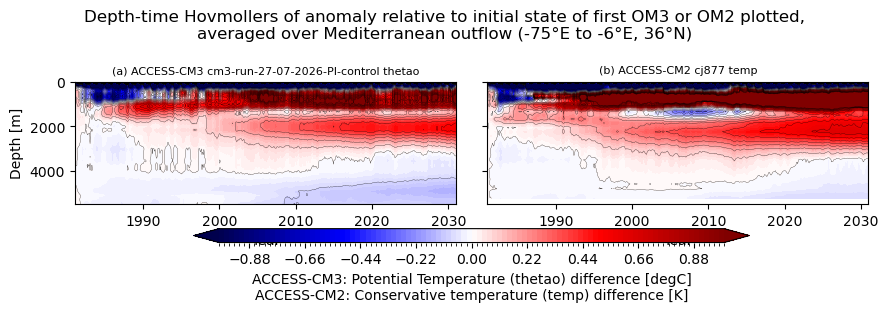

In [26]:
plot_anom(om3variable = "thetao",
        om2variable = "temp",
        vmax = 1)

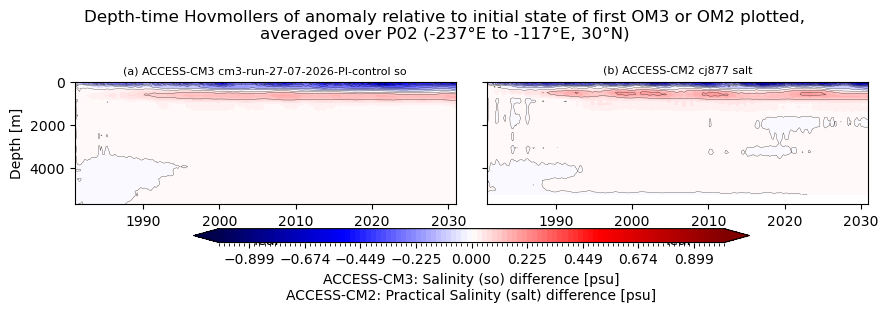

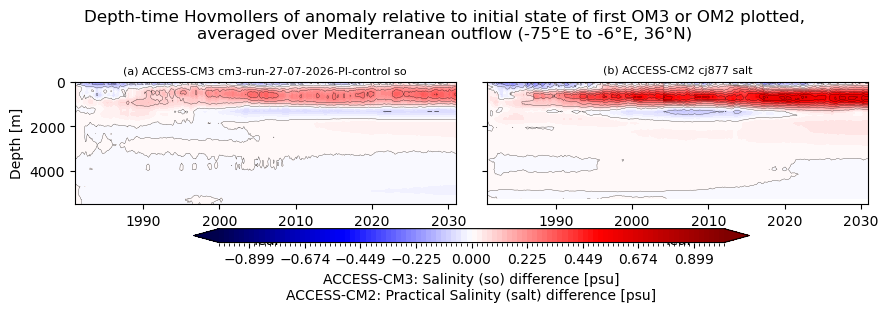

In [27]:
plot_anom(om3variable = "so",
        om2variable = "salt",
        mkmdfig=False)

Saved /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/temp-salt-vs-depth-time_03.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/temp-salt-vs-depth-time.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/temp-salt-vs-depth-time.md successfully.


Saved /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/temp-salt-vs-depth-time_04.png
Adding entry to per-notebook markdown: /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/temp-salt-vs-depth-time.md
This title already exists in the notebook markdown – appending an additional figure.
Lines appended to /g/data/tm70/cyb561/repos/claude/om3-in-cm3-submod/access-cm3-paper-1/notebooks/polished-python/mkfigs_output_cm3-run-27-07-2026-PI-control/mkmd/temp-salt-vs-depth-time.md successfully.


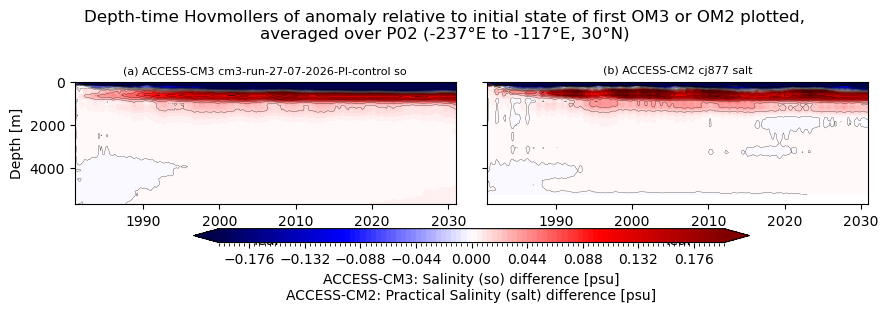

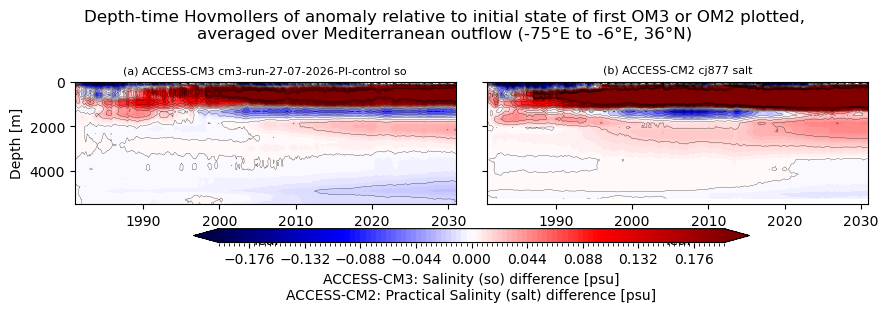

In [28]:
plot_anom(om3variable = "so",
        om2variable = "salt",
        vmax = 0.2)

In [29]:
def plot_anom_closeup(om3variable = "thetao",
            om2variable = "temp",
            vmax = None, mkmdfig=True):
    for region, d in om3vars_hov.items():
        npanels = len(d[om3variable]) + len(om2vars_hov[region][om2variable])
        nrows = (npanels+1)//2
        fig, axs = plt.subplots(nrows, 2,
                                figsize=(9, 3*nrows),
                                sharex=True, sharey=True)

        minx, maxx, miny, maxy = regions[region].values()
        if minx == maxx:
            regionstr = f'{minx}°E, {miny} to {maxy}°N'
        elif miny == maxy:
            regionstr = f'{minx}°E to {maxx}°E, {miny}°N'
        else:
            regionstr = f'{minx}°E to {maxx}°E, {miny}°N to {maxy}°N'

        fig.suptitle(f'Depth-time Hovmollers of anomaly relative to initial state of first OM3 or OM2 plotted,\naveraged over {region} ({regionstr})')

        if vmax == None: # calculate max abs over all panels (different for each region)
            vmax = 0
            for i, (expt, da) in enumerate(d[om3variable].items(), start=1):
                if i == 1:
                    ref = da.isel(time=0)  # use the same reference state for all om3 expts in this region
                vmax = max(vmax, abs(da - ref).max().data)
            for i2, (expt, da) in enumerate(om2vars_hov[region][om2variable].items(), start=i+1):
                if i2 == i+1:
                    ref = da.isel(time=0)  # use the same reference state for all om2 expts in this region
                vmax = max(vmax, abs(da - ref).max().data)

        # ACCESS-OM3 (or ACCESS-CM3)
        for i, (expt, da) in enumerate(d[om3variable].items(), start=1):
            plt.subplot(nrows, 2, i)
            if i == 1:
                ref = da.isel(time=0)  # use the same reference state for all om3 expts in this region
            p = (da - ref).transpose().plot.contourf(
                levels=101, vmin=-vmax, vmax=vmax, extend="both", cmap="seismic", add_colorbar=False,
            )
            (da - ref).transpose().plot.contour(
                levels=25, vmin=-vmax, vmax=vmax, add_colorbar=False, colors=["k"], linewidths=[0.2], linestyles=["-"]
            )
            try:
                tmax = min(tmax, max(da.time.data)) # earliest end time
            except UnboundLocalError:
                tmax = max(da.time.data)
            plt.gca().set_xlim([None, tmax])
            plt.gca().set_ylim([0, 1500])
            plt.gca().invert_yaxis()
            plt.title(f"({chr(ord('a')+i-1)}) {model_name} {expt} {om3variable}", fontsize=8)
            plt.xlabel('Year')
            plt.ylabel('Depth [m]')
            label = f"{model_name}: {da.attrs['long_name']} ({om3variable}) difference [{da.attrs['units']}]"
    
        # ACCESS-OM2 (or ACCESS-CM2)
        for i2, (expt, da) in enumerate(om2vars_hov[region][om2variable].items(), start=i+1):
            plt.subplot(nrows, 2, i2)
            if i2 == i+1:
                ref = da.isel(time=0)  # use the same reference state for all om2 expts in this region
            (da - ref).transpose().plot.contourf(
                levels=101, vmin=-vmax, vmax=vmax, extend="both", cmap="seismic", add_colorbar=False,
            )
            (da - ref).transpose().plot.contour(
                levels=25, vmin=-vmax, vmax=vmax, add_colorbar=False, colors=["k"], linewidths=[0.2], linestyles=["-"]
            )
            try:
                tmax = min(tmax, max(da.time.data)) # earliest end time
            except UnboundLocalError:
                tmax = max(da.time.data)
            plt.gca().set_xlim([None, tmax])
            plt.gca().set_ylim([0, 1500])
            plt.gca().invert_yaxis()
            plt.title(f"({chr(ord('a')+i2-1)}) {data_name} {expt} {om2variable}", fontsize=8)
            plt.xlabel('Year')
            plt.ylabel('Depth [m]')
            label += f"\n{data_name}: {da.attrs['long_name']} ({om2variable}) difference [{da.attrs['units']}]"
    
        try:  # drop empty subfigs (if any)
            fig.delaxes(axs.flatten()[i2])
        except IndexError:
            pass
        for ax in fig.get_axes():
            ax.label_outer()
        plt.tight_layout()
        fig.colorbar(p, ax=axs, orientation='horizontal',
                     fraction=.1, shrink=0.7, aspect=40,
                     label=label)
        if mkmdfig:
            mkmd.savefig(fig, "Horizontal mean temperature and salinity Hovmollers", 
                         f"{model_name} and {data_name} horizontal mean "+om3variable+" Hovmollers: drift from initial condition, vs depth and time. [GitHub issue: Hovmoller temperature anomaly (depth-time)](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/8)")            

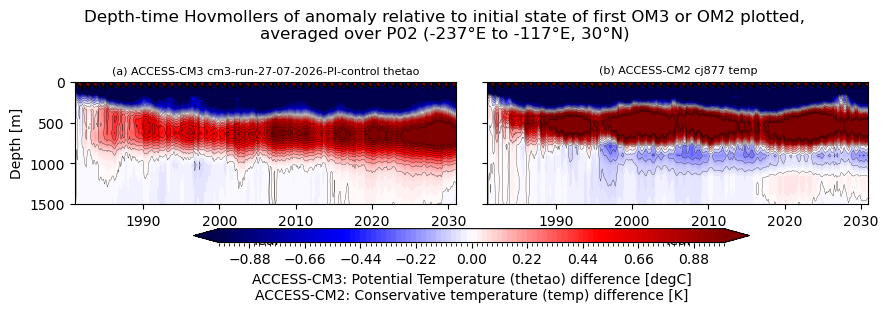

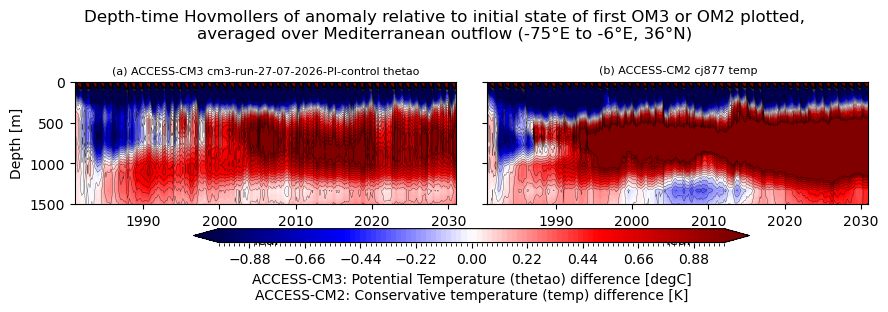

In [30]:
plot_anom_closeup(om3variable = "thetao",
        om2variable = "temp",
        vmax = 1,
        mkmdfig=False)

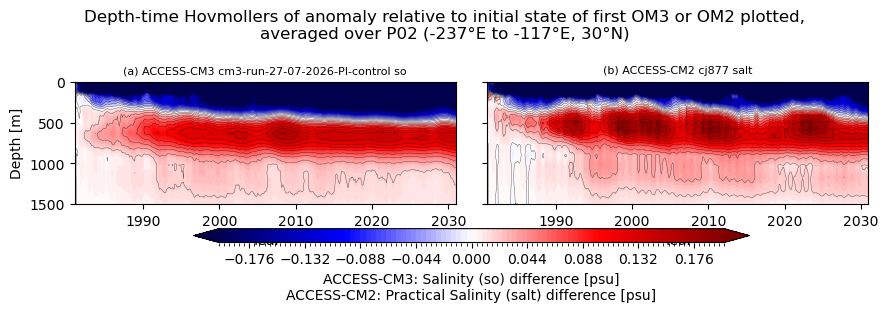

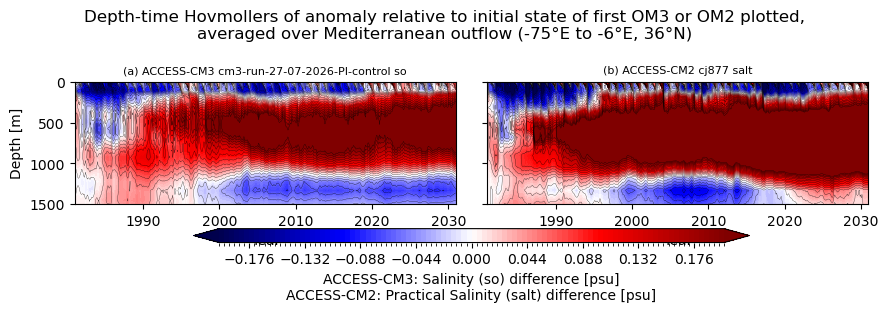

In [31]:
plot_anom_closeup(om3variable = "so",
        om2variable = "salt",
        vmax = 0.2,
        mkmdfig=False)

## Plot anomaly relative initial state of first OM3 plotted, minus that anomaly in the previous plot

In [32]:
def plot_anom_diff(om3variable = "thetao",
            om2variable = "temp",
            vmax = None, mkmdfig=True):
    for region, d in om3vars_hov.items():
        npanels = len(d[om3variable]) + len(om2vars_hov[region][om2variable])
        nrows = (npanels+1)//2
        fig, axs = plt.subplots(nrows, 2,
                                figsize=(9, 3*nrows),
                                sharex=True, sharey=True)

        minx, maxx, miny, maxy = regions[region].values()
        if minx == maxx:
            regionstr = f'{minx}°E, {miny} to {maxy}°N'
        elif miny == maxy:
            regionstr = f'{minx}°E to {maxx}°E, {miny}°N'
        else:
            regionstr = f'{minx}°E to {maxx}°E, {miny}°N to {maxy}°N'

        fig.suptitle(f'Depth-time Hovmollers of anomaly relative initial state of first OM3 plotted,\nminus that anomaly in the previous plot\naveraged over {region} ({regionstr})')

        # if vmax == None: # calculate max abs over all panels (different for each region)
        #     vmax = 0
        #     for i, (expt, da) in enumerate(d[om3variable].items(), start=1):
        #         if i == 1:
        #             ref = da.isel(time=0)  # use the same reference state for all om3 expts in this region
        #         vmax = max(vmax, abs(da - ref).max().data)
        #     for i2, (expt, da) in enumerate(om2vars_hov[region][om2variable].items(), start=i+1):
        #         if i2 == i+1:
        #             ref = da.isel(time=0)  # use the same reference state for all om2 expts in this region
        #         vmax = max(vmax, abs(da - ref).max().data)

        # ACCESS-OM3 (or ACCESS-CM3)
        for i, (expt, da) in enumerate(d[om3variable].items(), start=1):
            plt.subplot(nrows, 2, i)
            if i == 1:
                ref = da  # use the same reference state for all om3 expts in this region
                diff = (da - ref.isel(time=0)).load()
                diffref = 0
            else:
                diff = (da - ref.isel(time=0) - diffref).load()
            _diffref = diffref + diff
            diffref = _diffref
            p = diff.transpose().plot.contourf(
                levels=101, extend="both", cmap="seismic", add_colorbar=False,
            )
            diff.transpose().plot.contour(
                levels=25, add_colorbar=False, colors=["k"], linewidths=[0.2], linestyles=["-"]
            )
            try:
                tmax = min(tmax, max(da.time.data)) # earliest end time
            except UnboundLocalError:
                tmax = max(da.time.data)
            plt.gca().set_xlim([None, tmax])
            plt.gca().set_ylim([0, 1500])
            plt.gca().invert_yaxis()
            plt.title(f"({chr(ord('a')+i-1)}) {model_name} {expt} {om3variable}", fontsize=8)
            plt.xlabel('Year')
            plt.ylabel('Depth [m]')
            label = f"{model_name}: {da.attrs['long_name']} ({om3variable}) difference [{da.attrs['units']}]"
            fig.colorbar(p)

        # # ACCESS-OM2 (or ACCESS-CM2)
        # for i2, (expt, da) in enumerate(om2vars_hov[region][om2variable].items(), start=i+1):
        #     plt.subplot(nrows, 2, i2)
        #     if i2 == i+1:
        #         ref = da.isel(time=0)  # use the same reference state for all om2 expts in this region
        #     (da - ref).transpose().plot.contourf(
        #         levels=101, vmin=-vmax, vmax=vmax, extend="both", cmap="seismic", add_colorbar=False,
        #     )
        #     (da - ref).transpose().plot.contour(
        #         levels=25, vmin=-vmax, vmax=vmax, add_colorbar=False, colors=["k"], linewidths=[0.2], linestyles=["-"]
        #     )
        #     try:
        #         zmax = da["st_ocean"][np.where(np.isnan(da.isel(time=0)))[0][0] - 1]
        #         plt.gca().set_ylim([0, zmax])  # crop to deepest wet cell
        #     except IndexError:
        #         plt.gca().set_ylim([0, None])  # no dry cells so show all
        #     plt.gca().invert_yaxis()
        #     plt.title(f"({chr(ord('a')+i2-1)}) {data_name} {expt} {om2variable}", fontsize=8)
        #     plt.ylabel('Depth [m]')
        #     label += f"\n{data_name}: {da.attrs['long_name']} ({om2variable}) difference [{da.attrs['units']}]"
    
        try:  # drop empty subfigs (if any)
            fig.delaxes(axs.flatten()[i])
        except IndexError:
            pass
        for ax in fig.get_axes():
            ax.label_outer()
        plt.tight_layout()
        # fig.colorbar(p, ax=axs, orientation='horizontal',
        #              fraction=.1, shrink=0.7, aspect=40,
        #              label=label)
        # if mkmdfig:
        #     mkmd.savefig(fig, "Horizontal mean temperature and salinity Hovmollers", 
        #                  f"{model_name} and {data_name} horizontal mean "+om3variable+" Hovmollers: drift from initial condition, vs depth and time. [GitHub issue: Hovmoller temperature anomaly (depth-time)](https://github.com/ACCESS-Community-Hub/access-om3-paper-1/issues/8)")            

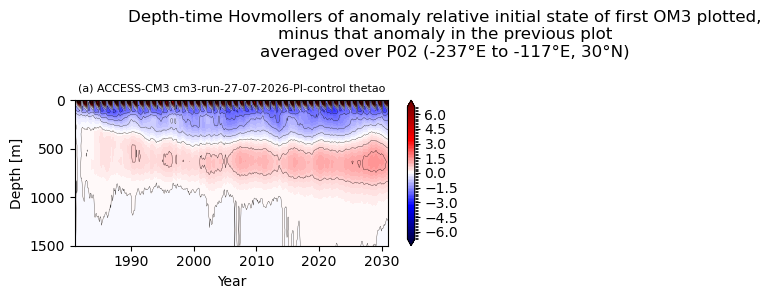

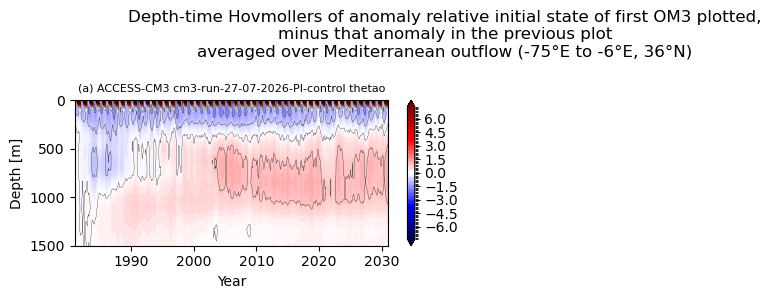

In [33]:
plot_anom_diff(om3variable = "thetao",
        om2variable = "temp",
        mkmdfig=False)

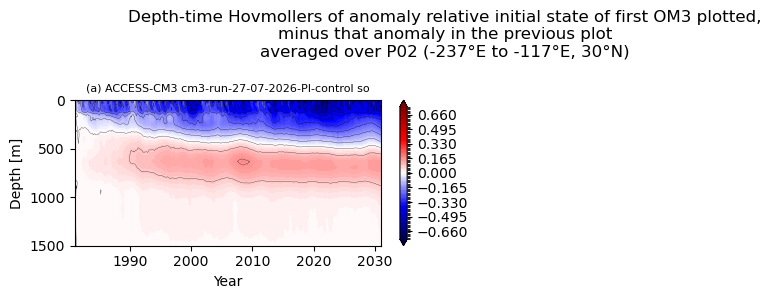

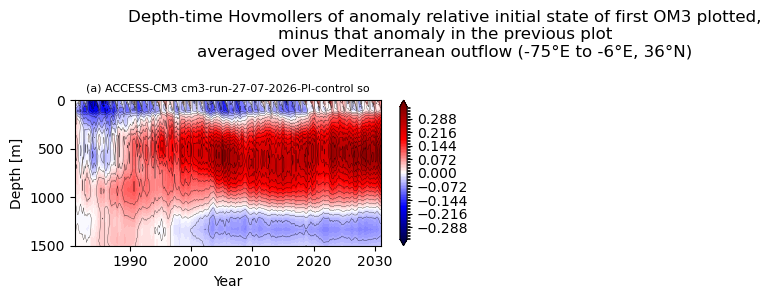

In [34]:
plot_anom_diff(om3variable = "so",
        om2variable = "salt",
        mkmdfig=False)

In [35]:
# client.close()